# OTSM and ODDM: a single carrier in the delay–Doppler plane

Section 2 of `otfs_sim` showed that with a rectangular pulse OTFS is **not** a multicarrier signal. Sample $l+nM$ of the frame is a combination of the $N$ symbols of a single delay row $l$:
$$s[l+nM]=\frac1{\sqrt N}\sum_kx[l,k]\,e^{\,j2\pi nk/N}.$$
The delay axis maps straight onto time — that is **a single carrier**. The only multicarrier part is along the Doppler axis, and only within a row. Two simplifications grow out of this:

**OTSM** (orthogonal time sequency multiplexing; Thaj, Viterbo, Hong, 2021) replaces the DFT along the Doppler axis with the **Walsh–Hadamard transform**. The matrix is $\pm1$: the modulator needs only additions, and so does the receiver. The $k$ axis is now not Doppler but **sequency** (the number of sign changes of a Walsh function). A Doppler shift is no longer a shift in $k$, but the time-domain channel is the same, and with linear reception ($H$ is the same up to a unitary rotation) the error probability is almost the same.

**ODDM** (orthogonal delay-Doppler division multiplexing; Lin, Yuan, 2022) comes from the other side: it takes the OTFS samples and shapes each one with a **root-Nyquist pulse** of width $T/M$ instead of a rectangular window of length $T$ per "OFDM symbol". The result is ordinary single-carrier transmission with an RRC filter. The spectrum is compact, and the pulse $u(t)=\sum_n a(t-nT)$ is orthogonal to its own shifts on the lattice $(mT/M,\;n/NT)$ — a **DD-orthogonal pulse**, whose existence was debated for a long time.

The last notebook in the series: OTFS (`otfs_sim`) → Zak-OTFS (`zak_sim`) → AFDM (`afdm_sim`) / OCDM (`ocdm_sim`) → OTSM/ODDM.

1. Walsh functions and a single carrier along delay · 2. The channel in the delay–sequency domain · 3. BER: OTSM vs OTFS · 4. ODDM: spectrum and DD orthogonality

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc
from scipy.linalg import hadamard

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # delay × Doppler/sequency, as in otfs_sim
DF = 15e3
L_CP = 8
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5
BETA = 0.25            # roll-off of the ODDM RRC pulse
FRAMES = 30

rng = np.random.default_rng(SEED)

## Primitives: Walsh–Hadamard (fast), OTFS/OTSM frames, channel, effective matrix

In [2]:
MN = M * N
FS = M * DF; T = 1 / DF
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, MN, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- Walsh–Hadamard in sequency order (number of sign changes) ----------
H_N = hadamard(N)
SEQ = np.argsort([np.sum(np.diff(r) != 0) for r in H_N])
WAL = H_N[SEQ] / np.sqrt(N)                      # row k is the Walsh function with k sign changes

def fwht(a):
    """fast WHT along the last axis: only additions and subtractions, N·log₂N operations"""
    a = a.copy(); h = 1
    while h < a.shape[-1]:
        a = a.reshape(a.shape[:-1] + (-1, 2, h))
        a = np.concatenate([a[..., 0, :] + a[..., 1, :], a[..., 0, :] - a[..., 1, :]], -1)
        a = a.reshape(a.shape[:-2] + (-1,)); h *= 2
    return a

# ---------- three ways to turn the DD grid into a signal ----------
def frame(x, kind):
    """x[l,k] (…, M·N) → N blocks of M samples + one CP. 'otfs': IDFT along k; 'otsm': WHT along k."""
    X = x.reshape(x.shape[:-1] + (M, N))
    B = np.fft.ifft(X, axis=-1) * np.sqrt(N) if kind == "otfs" else X @ WAL      # column n is block n
    s = B.swapaxes(-1, -2).reshape(x.shape[:-1] + (MN,))
    return np.concatenate([s[..., -L_CP:], s], -1)

def unframe(r, kind):
    Y = r[..., L_CP:L_CP + MN].reshape(r.shape[:-1] + (N, M)).swapaxes(-1, -2)
    Z = np.fft.fft(Y, axis=-1) / np.sqrt(N) if kind == "otfs" else Y @ WAL.T
    return Z.reshape(r.shape[:-1] + (MN,))

def draw_paths(rng):
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, kind):
    return unframe(channel(frame(np.eye(MN, dtype=complex), kind), paths), kind).T

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# self-checks
assert np.allclose(WAL @ WAL.T, np.eye(N)), "WHT"
_a = crandn((3, N), rng)
assert np.allclose(fwht(_a)[:, SEQ] / np.sqrt(N), _a @ WAL.T), "fast WHT"
_b, _x = qpsk_bits(2, rng)
for kind in ("otfs", "otsm"):
    assert np.allclose(unframe(frame(_x, kind), kind), _x)
print(f"Grid {M}×{N}, ν_max = {NU_MAX:.0f} Hz = {NU_MAX*N*T:.2f} bins of 1/(NT); CP {L_CP} samples per frame")

Grid 64×16, ν_max = 1852 Hz = 1.98 bins of 1/(NT); CP 8 samples per frame


## 1. Walsh functions and a single carrier along delay
Left: the Walsh functions in sequency order: row $k$ changes sign exactly $k$ times. They are "discrete sinusoids" made of $\pm1$, and they are orthogonal. Right: one symbol $(l,k)$ in time for OTFS and for OTSM: in both cases it is $N$ pulses at positions $l+nM$. Only the coefficients differ: $e^{j2\pi nk/N}$ (a rotating phase) vs $\pm1$ (a Walsh function).

The OTFS modulator per frame is $M$ DFTs of length $N$: $\tfrac{MN}{2}\log_2N$ complex multiplications. The OTSM modulator is $M$ fast WHTs: **no multiplications at all**, $MN\log_2N$ additions. numpy does not show this: both are fast, and the FFT is even faster thanks to an optimized library. The gain appears in hardware, where a multiplier costs several times more area and energy than an adder.

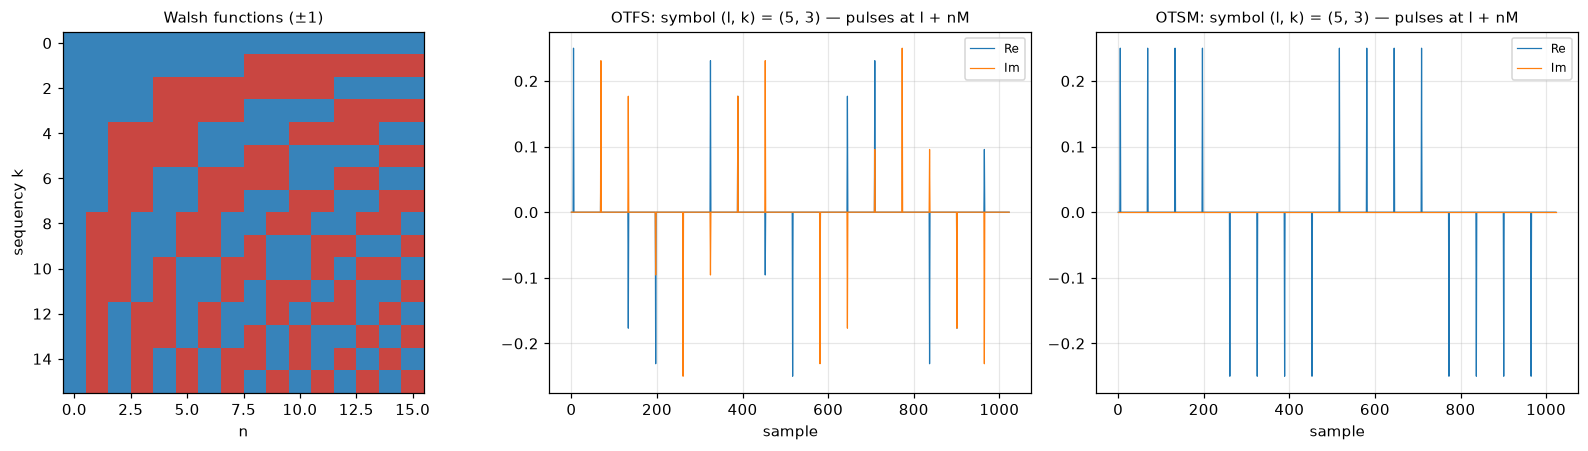

Sign changes per row: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Both are a single carrier along delay: symbol (l, k) lives only in samples l + nM; only the pulse coefficients differ: e^(j2πnk/N) for OTFS, ±1 for OTSM
Modulator per frame: IDFT_N — 2048 complex multiplications + as many additions; WHT_N — 0 multiplications and 4096 additions
(numpy timing proves nothing: FFT 0.008 ms/frame vs WHT 0.028 ms/frame — WHT pays off in hardware, where a multiplier costs more than an adder)


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].imshow(WAL * np.sqrt(N), cmap="RdBu", vmin=-1.5, vmax=1.5); ax[0].grid(False)
ax[0].set_xlabel("n"); ax[0].set_ylabel("sequency k"); ax[0].set_title("Walsh functions (±1)", fontsize=10)
l0, k0 = 5, 3
for a, kind, t in ((ax[1], "otfs", "OTFS"), (ax[2], "otsm", "OTSM")):
    x = np.zeros(MN, complex); x[l0 * N + k0] = 1
    s = frame(x, kind)[L_CP:]
    a.plot(np.arange(MN), s.real, "C0", lw=0.8, label="Re"); a.plot(np.arange(MN), s.imag, "C1", lw=0.8, label="Im")
    a.set_xlabel("sample"); a.legend(fontsize=8)
    a.set_title(f"{t}: symbol (l, k) = ({l0}, {k0}) — pulses at l + nM", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Sign changes per row: {[int(np.sum(np.diff(r) != 0)) for r in WAL]}")
print(f"Both are a single carrier along delay: symbol (l, k) lives only in samples l + nM; only the pulse coefficients differ: e^(j2πnk/N) for OTFS, ±1 for OTSM")

# modulator complexity
B = 200; _, xb = qpsk_bits(B, rng); Xb = xb.reshape(B, M, N)
t = time.perf_counter(); [np.fft.ifft(Xb, axis=-1) for _ in range(20)]; t_fft = (time.perf_counter() - t) / 20
t = time.perf_counter(); [fwht(Xb) for _ in range(20)]; t_wht = (time.perf_counter() - t) / 20
print(f"Modulator per frame: IDFT_N — {M*N//2*int(np.log2(N))} complex multiplications + as many additions; WHT_N — 0 multiplications and {M*N*int(np.log2(N))} additions")
print(f"(numpy timing proves nothing: FFT {t_fft*1e3/B:.3f} ms/frame vs WHT {t_wht*1e3/B:.3f} ms/frame — WHT pays off in hardware, where a multiplier costs more than an adder)")

## 2. The channel in the delay–sequency domain
The pilot response: for OTFS, Doppler is a shift along the $k$ axis, and the response is compact. For OTSM, Doppler "mixes" sequencies: Walsh functions are not eigenfunctions of a frequency shift, and the response spreads over more values of $k$, i.e. the channel matrix is **less sparse**: 99 % of a row's energy sits in 34 entries vs 25 for OTFS. That is why OTSM receivers work in the **time** domain (iterative Gauss–Seidel on the sparse time-domain matrix, Thaj et al.) rather than on the response in the DS domain.

Yet the singular values of $H_\text{OTSM}$ and $H_\text{OTFS}$ coincide to machine precision. Both matrices are the same time-domain channel rotated by different unitary transforms. The capacity is the same, and linear detectors differ only in how the error is distributed over the symbols.

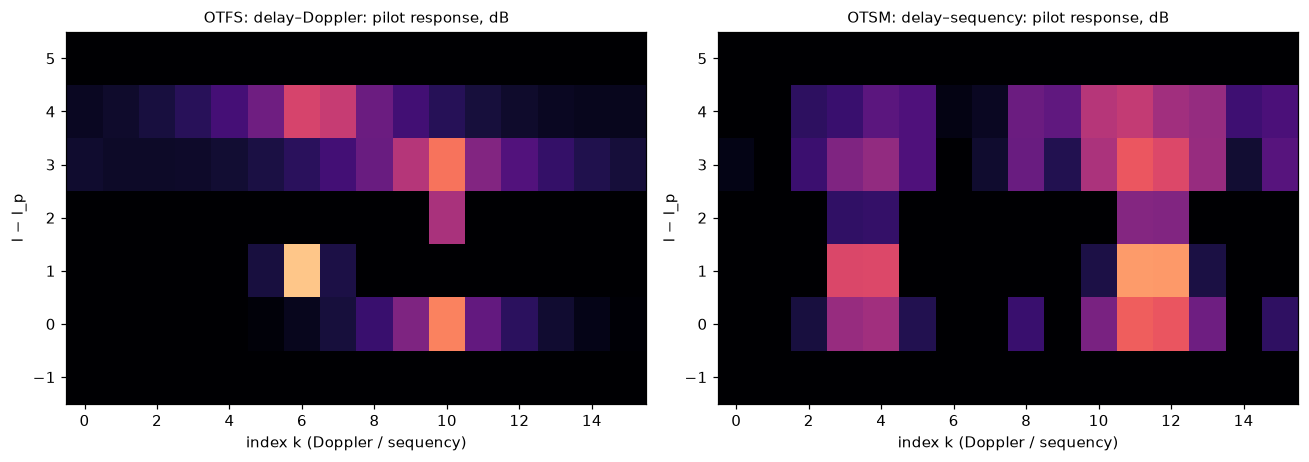

OTFS: entries per row holding 99 % of the energy — 25.0 (of 1024)
OTSM: entries per row holding 99 % of the energy — 34.2 (of 1024)


The singular values coincide (both are unitary re-mappings of one time-domain channel): max|σ_OTFS − σ_OTSM| = 8.9e-15


In [4]:
pth = draw_paths(np.random.default_rng(4))
Ho, Hs = eff_matrix(pth, "otfs"), eff_matrix(pth, "otsm")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
lp, kp = M // 2, N // 2
for a, Hm, t in ((ax[0], Ho, "OTFS: delay–Doppler"), (ax[1], Hs, "OTSM: delay–sequency")):
    col = np.abs(Hm[:, lp * N + kp]).reshape(M, N)
    a.imshow(20 * np.log10(col[lp - 1:lp + P_PATHS + 1] + 1e-6), origin="lower", aspect="auto", cmap="magma", vmin=-40, vmax=0,
             extent=[-0.5, N - 0.5, -1.5, P_PATHS + 0.5])
    a.set_xlabel("index k (Doppler / sequency)"); a.set_ylabel("l − l_p"); a.set_title(f"{t}: pilot response, dB", fontsize=10); a.grid(False)
plt.tight_layout(); plt.show()
for nm, Hm in (("OTFS", Ho), ("OTSM", Hs)):
    e = np.sort(np.abs(Hm)**2, 1)[:, ::-1]; e = np.cumsum(e, 1) / e.sum(1, keepdims=True)
    print(f"{nm}: entries per row holding 99 % of the energy — {np.mean(np.argmax(e > 0.99, 1) + 1):.1f} (of {MN})")
print(f"The singular values coincide (both are unitary re-mappings of one time-domain channel): max|σ_OTFS − σ_OTSM| = {np.max(np.abs(np.linalg.svd(Ho, compute_uv=False) - np.linalg.svd(Hs, compute_uv=False))):.1e}")

## 3. BER: OTSM vs OTFS
The same channel (500 km/h, 5 paths, fractional Doppler), LMMSE for both. The curves practically coincide: each OTSM symbol, like each OTFS symbol, is spread over all $N$ blocks of the frame, i.e. over time. It collects the Doppler diversity just the same. The result of Thaj et al. is reproduced: OTSM gives the same BER as OTFS with a multiplier-free modulator.

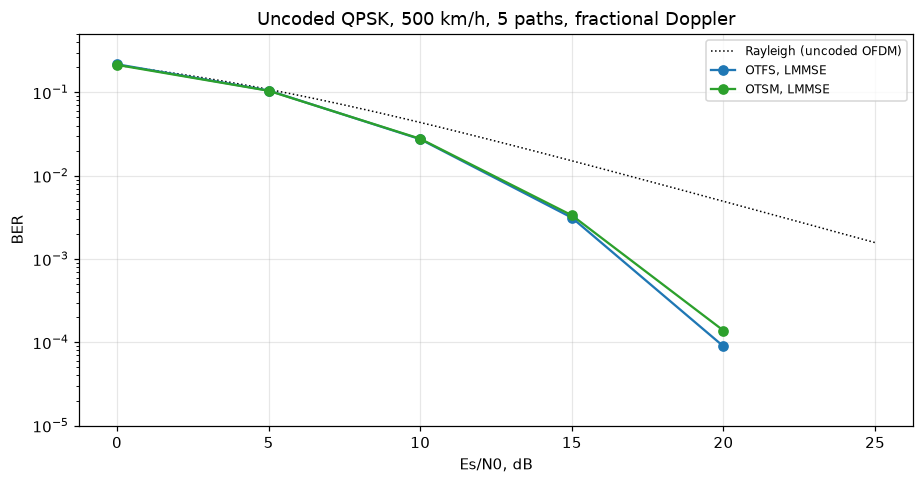

SNR  0 dB: OTFS 2.2e-01, OTSM 2.1e-01
SNR  5 dB: OTFS 1.1e-01, OTSM 1.0e-01
SNR 10 dB: OTFS 2.7e-02, OTSM 2.8e-02
SNR 15 dB: OTFS 3.1e-03, OTSM 3.3e-03
SNR 20 dB: OTFS 9.0e-05, OTSM 1.4e-04
SNR 25 dB: OTFS 0.0e+00, OTSM 0.0e+00


In [5]:
snrs = np.arange(0, 26, 5)
ber = {k: np.zeros(len(snrs)) for k in ("otfs", "otsm")}
for f in range(FRAMES):
    pth = draw_paths(rng)
    for kind in ber:
        H = eff_matrix(pth, kind); b, x = qpsk_bits(2, rng)
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            y = x @ H.T + np.sqrt(n0) * crandn(x.shape, rng)
            ber[kind][i] += np.mean(hard_bits(lmmse(H, y, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
sg = np.linspace(0, 25, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Rayleigh (uncoded OFDM)")
for k, c in (("otfs", "C0"), ("otsm", "C2")):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], c + "o-", label=f"{k.upper()}, LMMSE")
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"Uncoded QPSK, {SPEED_KMH} km/h, {P_PATHS} paths, fractional Doppler")
plt.tight_layout(); plt.show()
for i, snr in enumerate(snrs):
    print(f"SNR {snr:2d} dB: OTFS {ber['otfs'][i]:.1e}, OTSM {ber['otsm'][i]:.1e}")

## 4. ODDM: spectrum and DD orthogonality
**Spectrum.** OTFS as a precoder over OFDM is a sum of subcarriers with a rectangular envelope of length $T$. Each has a sinc spectrum with $\propto1/f$ tails, and the out-of-band emission is large. ODDM sends **the same samples** on a single carrier with an RRC filter (roll-off $\beta=0.25$): beyond the band edge $(1+\beta)M\Delta f/2$ only −50 dB of the power remains, vs −26 dB for OTFS (the power share beyond $\pm0.7M\Delta f$).

**DD orthogonality.** The ambiguity function of the pulse $u(t)=\sum_{n=0}^{N-1}a(t-nT)$ on the lattice
$$A_u\!\left(m\tfrac{T}{M},\,\tfrac{n}{NT}\right)=\int u(t)\,u^*\!\left(t-m\tfrac{T}{M}\right)e^{-j2\pi\frac{n}{NT}t}\,dt$$
is zero everywhere except at the origin. In delay this comes from the Nyquist property of $a\star a$ at spacing $T/M$; in Doppler, from the $N$ pulses spaced $T$ apart summing with phases $e^{-j2\pi nk/N}$ to zero. The side samples are below −80 dB, and that is only the truncation of the RRC tail at ±8 samples. For a long time it was believed that no orthogonal pulse with resolution exactly $(T/M,1/NT)$ exists (because of the uncertainty principle). ODDM gets around this because the pulse is orthogonal **only on the lattice** and has a bandwidth and duration larger than $M/T$ and $NT$ ($\beta$ and the tails).

OTFS (OFDM, rectangle T)          : power share beyond ±0.7·MΔf (the RRC edge is at 0.625) -25.5 dB
ODDM (RRC, β = 0.25)              : power share beyond ±0.7·MΔf (the RRC edge is at 0.625) -49.7 dB


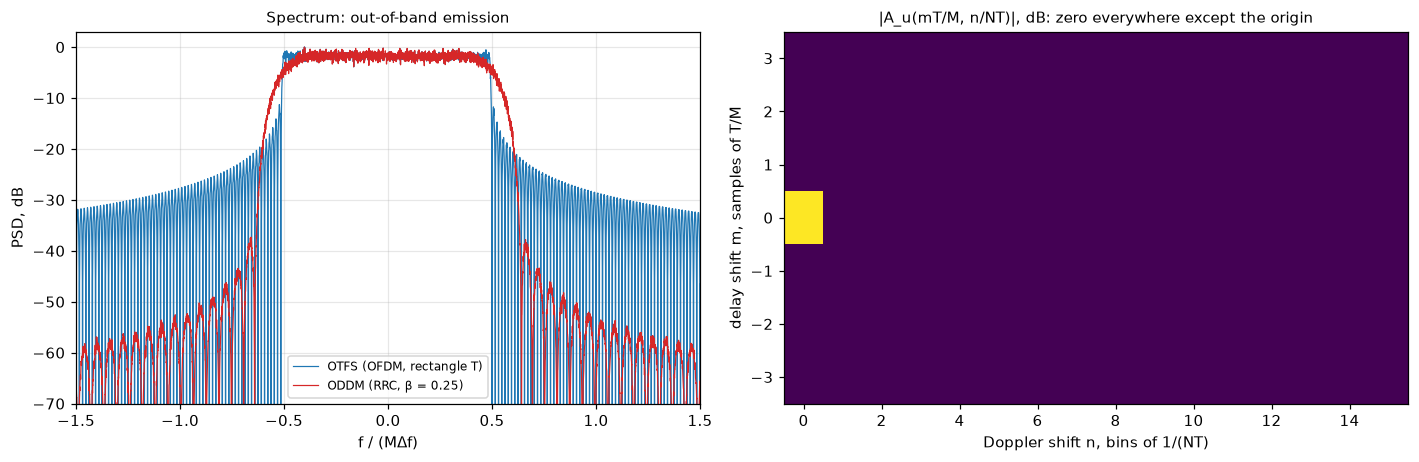

Largest off-origin ambiguity sample on the lattice: -82 dB (the RRC tail is cut at ±8 samples)


In [6]:
# ODDM: the same samples, but each one is an RRC pulse of width T/M instead of a rectangular T window per "OFDM symbol"
OS, SPAN = 8, 8
def rrc(beta, span=SPAN, os=OS):
    t = np.arange(-span * os, span * os + 1) / os
    with np.errstate(divide="ignore", invalid="ignore"):
        h = (np.sin(np.pi * t * (1 - beta)) + 4 * beta * t * np.cos(np.pi * t * (1 + beta))) / (np.pi * t * (1 - (4 * beta * t)**2))
    h[t == 0] = 1 - beta + 4 * beta / np.pi
    tb = np.isclose(np.abs(t), 1 / (4 * beta))
    h[tb] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
    return h / np.sqrt(np.sum(h**2))
g = rrc(BETA)

def oddm_wave(x):
    s = frame(x, "otfs")                                       # the samples are the same as OTFS
    up = np.zeros(s.shape[:-1] + (s.shape[-1] * OS,), complex); up[..., ::OS] = s
    return np.apply_along_axis(lambda v: np.convolve(v, g), -1, up)

def otfs_mc_wave(x):
    """OTFS as a precoder over OFDM: each subcarrier is a rectangle of duration T (a sinc spectrum)"""
    X = x.reshape(x.shape[:-1] + (M, N))
    Xtf = np.fft.ifft(np.fft.fft(X, axis=-2), axis=-1)          # ISFFT
    G = np.zeros(x.shape[:-1] + (M * OS, N), complex)
    G[..., :M // 2, :] = Xtf[..., :M // 2, :]; G[..., -M // 2:, :] = Xtf[..., M // 2:, :]
    return (np.fft.ifft(G, axis=-2) * OS).swapaxes(-1, -2).reshape(x.shape[:-1] + (-1,))

B = 60; _, xb = qpsk_bits(B, rng)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for k, w, c in (("OTFS (OFDM, rectangle T)", otfs_mc_wave(xb), "C0"), (f"ODDM (RRC, β = {BETA})", oddm_wave(xb), "C3")):
    L = 2 ** int(np.ceil(np.log2(w.shape[-1])))
    P = np.mean(np.abs(np.fft.fft(w, L, axis=-1))**2, 0); P = np.fft.fftshift(P) / P.max()
    f = np.fft.fftshift(np.fft.fftfreq(L, 1 / (FS * OS)))
    ax[0].plot(f / (M * DF), 10 * np.log10(P + 1e-12), c, lw=0.8, label=k)
    oob = np.sum(P[np.abs(f) > 0.7 * M * DF]) / np.sum(P)
    print(f"{k:34}: power share beyond ±0.7·MΔf (the RRC edge is at 0.625) {10*np.log10(oob):.1f} dB")
ax[0].set_xlim(-1.5, 1.5); ax[0].set_ylim(-70, 3); ax[0].set_xlabel("f / (MΔf)"); ax[0].set_ylabel("PSD, dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Spectrum: out-of-band emission", fontsize=10)
# DD orthogonality: the ambiguity function of the RRC pulse on the lattice (mT/M, n/(NT))
pulse = np.zeros(N * M * OS, complex)
for n in range(N):
    pulse[n * M * OS: n * M * OS + len(g)] += g                # u(t) = Σ_n a(t − nT): N RRC pulses every T
tt = np.arange(len(pulse))
A = np.zeros((7, N))
for mi, m in enumerate(range(-3, 4)):
    sh = np.roll(pulse, m * OS)
    for n in range(N):
        A[mi, n] = np.abs(np.sum(pulse * np.conj(sh) * np.exp(-2j * np.pi * n * tt / (N * M * OS))))
A /= A[3, 0]
ax[1].imshow(20 * np.log10(A + 1e-9), origin="lower", aspect="auto", cmap="viridis", vmin=-60, vmax=0, extent=[-0.5, N - 0.5, -3.5, 3.5])
ax[1].set_xlabel("Doppler shift n, bins of 1/(NT)"); ax[1].set_ylabel("delay shift m, samples of T/M"); ax[1].grid(False)
ax[1].set_title("|A_u(mT/M, n/NT)|, dB: zero everywhere except the origin", fontsize=10)
plt.tight_layout(); plt.show()
A2 = A.copy(); A2[3, 0] = 0
print(f"Largest off-origin ambiguity sample on the lattice: {20*np.log10(A2.max()):.0f} dB (the RRC tail is cut at ±{SPAN} samples)")

## Series wrap-up: waveforms for Doppler channels
| | OFDM | OTFS 1.0 | Zak-OTFS | AFDM | OCDM | OTSM | ODDM |
|---|---|---|---|---|---|---|---|
| Where symbols live | TF | DD | DD (Zak lattice) | DAFT, 1-D | chirps, 1-D | delay–sequency | DD |
| Pulse | rectangle $T$ | rectangle $T$ | Gaussian/sinc/RRC in DD | — | — | rectangle | RRC of width $T/M$ |
| Modem | IFFT | ISFFT + IFFT | Zak | IFFT + 2 diagonals | IFFT + 1 diagonal | WHT (no multiplications) | IDFT over Doppler + RRC |
| Path diversity | no | yes | yes | yes | partial | yes | yes |
| Fractional Doppler | ICI | estimation floor | predictable | estimation floor | ICI | as OTFS | as OTFS |
| Spectrum | sinc tails | sinc tails | set by the filter | sinc tails | sinc tails | set by the filter | compact |
| Notebook | `lte_sim` | `otfs_sim` | `zak_sim` | `afdm_sim` | `ocdm_sim` | here | here |

The overall conclusion of the series: with linear reception, a waveform is a unitary transform of one and the same time-domain channel. The capacity is the same for all (section 2); three things differ:
1. **how a symbol is distributed over the paths**, i.e. how much uncoded diversity the detector gets: none for OFDM, full for OTFS/AFDM/OTSM;
2. **how sparse and predictable the channel is in its "own" domain**, i.e. what estimation and detection cost: OTFS is sparse for integer Doppler, Zak-OTFS is predictable for any Doppler, AFDM is sparse in 1-D;
3. **what the modem costs and how much it emits outside the band**: OTSM needs no multiplications, ODDM has a compact spectrum.

With a good code and interleaving, OFDM (`lte_sim`) collects most of the same diversity, so all these schemes are candidates for high-Doppler scenarios (trains, aircraft, LEO satellites, V2X), for sensing (ISAC) and for 6G, not a replacement for OFDM everywhere.

## Things to try
- `N = 64` — the OTSM modulator saves even more multiplications ($\log_2N$ grows); BER still matches OTFS
- `BETA = 0.05` — the ODDM spectrum is almost rectangular, but the pulse is longer: with the same ±8-sample truncation the ambiguity side samples rise
- `BETA = 0.5` — even lower out-of-band emission, but 50 % more bandwidth
- `SPEED_KMH = 30` — Doppler is small, and the OTSM response in section 2 is almost as compact as OTFS's (WHT and DFT agree on the constant function, $k=0$)
- `P_PATHS = 2` — less diversity for both schemes; the section 3 curves are shallower but still together